# 6. Ordinary Differential Equations

$$ % Latex macros
\newcommand{\mat}[1]{\begin{pmatrix} #1 \end{pmatrix}}
\newcommand{\p}[2]{\frac{\partial #1}{\partial #2}}
\newcommand{\b}[1]{\boldsymbol{#1}}
\newcommand{\w}{\boldsymbol{w}}
\newcommand{\x}{\boldsymbol{x}}
\newcommand{\y}{\boldsymbol{y}}
$$

A differential equation is an equation that includes a derivative $\frac{df(x)}{dx}$ of an unknown function $f(x)$.  

The derivative means the slope, mathematically defined as the limit:

$$
\frac{df(x)}{dx} = \lim_{\Delta x \rightarrow 0} \frac{f(x+\Delta x) - f(x)}{\Delta x}
$$

A differential equation including a derivative by only one variable is called an *ordinary differential equation (ODE)*.

Here we consider ODEs of the form

$$ \frac{dy}{dt} = f(y, t) $$

which describes the temporal dynamics of a varibale $y$ over time $t$.  It is also called a continuous-time *dynamical system*.

Finding the variable as an explicit function of time $y(t)$ is called *solving* or *integrating* the ODE.
When it is done numerically, it is aslo called *simulating*.

**References:**
* [Strogatz SH (2024). Nonlinear Dynamics And Chaos](https://doi.org/10.1201/9780429398490).  
* [Scientific Python Lectures: Section 1.5.7 Numerical Integration](https://lectures.scientific-python.org)


## Basics of derivatives

Here are some basic properties of the derivative $f'(x)=\frac{df(x)}{dx}$

* The derivative of a polynomial:

$$ (x^n)' = n x^{n-1} $$

* The derivative of exponential is itself:

$$ (e^x)' = e^x $$

* Derivatives of sine and cosine:

$$ \sin'(x)=\cos(x),$$

$$ \cos'(x)=-\sin(x) $$

* Linearity:

$$ (af(x)+bg(x))' = af'(x)+bg'(x) $$

* Chain rule:

$$ (f(g(x))' = f'(g(x))g'(x) $$


### Second-order derivative

The second-order derivative $\frac{d^2f(x)}{dx^2}$ of a function $f(x)$ is the derivative of the derivative:

$$
\frac{d^2f(x)}{dx^2} = \frac{d}{dx}\frac{df(x)}{dx}
= \lim_{\Delta x \rightarrow 0} \frac{f(x+\Delta x) - 2f(x) + f(x-\Delta x)}{\Delta x^2}
$$

A second-order derivative represents the change in the slope, i.e., the curvature.

## Analytic Solutions
Solving a differential equation is an inverse problem of differentiation, for which analytic solution may not be available.  

The simplest case where analytic solutions are available is *linear* differential equations

$$ \frac{dy}{dt} = A y $$

where $y$ is a real variable or a real vector, and $A$ is a constant coefficient or a matrix.  

### Linear ODEs
In general, a differential equation can have multiple solutions. For example, for a scalar linear ODE

$$ \frac{dy(t)}{dt} = a y(t), $$

a solution is given by

$$ y(t) = e^{at}. $$

Finding a solution of an ODE is generally not easy, but verifying a solution is relatively easy. In the above case, you can verify it by the chain rule as :

$$ \frac{dy(t)}{dt} = \frac{de^{at}}{dt} = \left.\frac{de^{x}}{dx}\right|_{x=at}\frac{dat}{dt} = e^{at}a = a y(t). $$

However, this is not the only solution. In fact, all scaled variants

$$ y(t) = C e^{at}, $$

where $C$ can be any real value, are solutions.  
* Verify that by differentiating both sides of the equaiton above.

When the value of $y(t)$ at a certain time $t$ is specified, the solution becomes unique.  
For example, by specifying an initial condition

$$ y(0)=3, $$

from $e^{a0}=e^0=1$, we have $C=3$ and a particular solution $$ y(t)=3e^{at} $$ is determined.

Finding a solution from a given initial value $y(0)$ is called an *initial value problem*.

For a second-order linear ODE

$$ \frac{d^2y}{dt^2} = -a^2 y, $$

the solution is given by

$$ y(t) = C_1 \sin at + C_2 \cos at $$

where $C_1$ and $C_2$ are determined by specifying $y$ and $dy/dt$ at certain time.

* Also verify this by differentiation.

### Analytically solvable ODEs
Other cases where analytic solutions are well known are:

* Linear time-varying coefficient:

$$ \frac{dy}{dt} = a(t)y $$

$at$ replaced by time integral $\int a(t)dt$

$$ y(t) = C e^{\int a(t)dt} $$

* Linear time-varying input:

$$\frac{dy}{dt} = a(t)y + b(t)$$

using the above solution $y_0(t)$ for $b(t)=0$

$$ y(t) = Cy_0(t) + y_0(t) \int \frac{b(t)}{y_0(t)}dt $$

* Separation of variables:

$$\frac{dy}{dt} = a(y)b(t)$$

two related integrals

$$\int \frac{1}{a(y)}dy = \int b(t)dt + C $$

* Other cases that can be reduced to above by change of variables, etc.

You can use `dsolve()` function of `SymPy` to find some analitic solutions.  See Scipy Tutorial, Chapter 16 if you are interested.

## Euler Method
The most basic way of solving an ODE numerically is *Euler Method*.  
For an ODE

$$ \frac{dy}{dt} = f(y,t), $$

we approximate the derivative with the finite difference

$$ \frac{dy}{dt} \simeq \frac{y(t+\Delta t) - y(t)}{\Delta t} = f(y,t) $$

and reorder this to predict $ y(t+\Delta t) $ as

$$ y(t+\Delta t) = y(t) + f(y,t) \Delta t. $$

We can use this iteratively from an initial value $y(0)$ with a small time step $\Delta t$ to approximate the solution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def euler(f, y0, dt, n, *args):
    """f: righthand side of ODE dy/dt=f(y,t)
        y0: initial condition y(0)=y0
        dt: time step
        n: iteratons
        args: parameter for f(y,t,*args)"""
    d = np.array([y0]).size  ## state dimension
    y = np.zeros((n+1, d))
    y[0] = y0
    t = 0
    for k in range(n):
        y[k+1] = y[k] + f(y[k], t, *args)*dt
        t = t + dt
    return y

Let us test this with a first-order linear ODE.

In [3]:
def first(y, t, a):
    """first-order linear ODE dy/dt = a*y"""
    return a*y

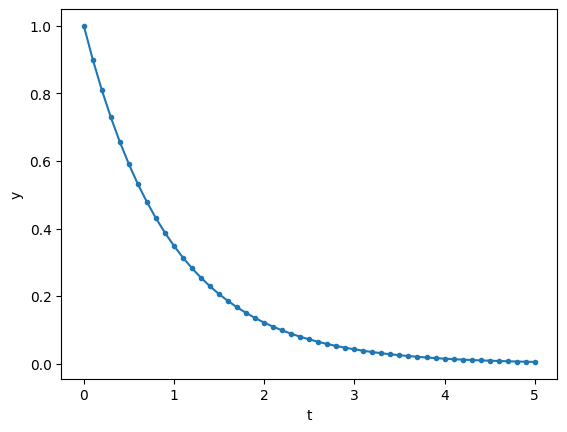

In [4]:
dt = 0.1 # time step
T = 5    # time span
n = int(T/dt)  # steps
t = np.linspace(0, T, n+1)
y = euler(first, 1, dt, n, -1)
plt.plot(t, y, '.-')
plt.xlabel('t'); plt.ylabel('y');

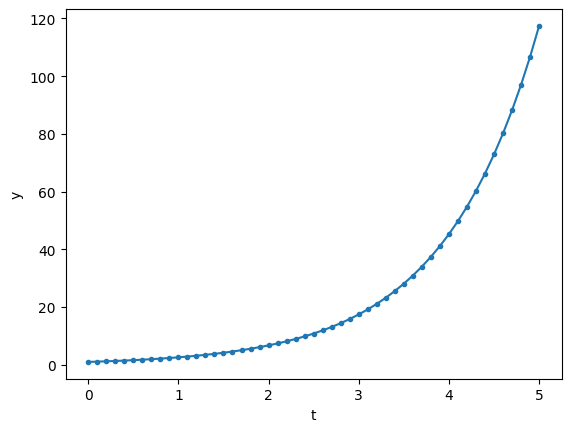

In [5]:
y = euler(first, 1, dt, n, 1)
plt.plot(t, y, '.-')
plt.xlabel('t'); plt.ylabel('y');

A second-order ODE

$$ \frac{d^2y}{dt^2} = a_2 \frac{dy}{dt} + a_1 y + a_0 $$

can be converted into a first-order ODE of a 2-dimensional vector
${\bf y} = \pmatrix{y_1 \\ y_2} =\pmatrix{y \\ \frac{dy}{dt}}$ as

$$ \frac{dy_1}{dt} = y_2 $$

$$ \frac{dy_2}{dt} = a_2 y_2 + a_1 y_1 + a_0 $$

or in a vector-matrix form

$$ \frac{d}{dt}{\bf y} = A{\bf y} + {\bf b}$$

where

$$ A = \pmatrix{0 & 1 \\ a_1 & a_2} \mbox{ and } {\bf b} = \pmatrix{0 \\ a_0}$$

In [6]:
def second(y, t, a):
    """second-order linear ODE """
    y1, y2 = y
    return np.array([y2, a[2]*y2 + a[1]*y1 + a[0]])

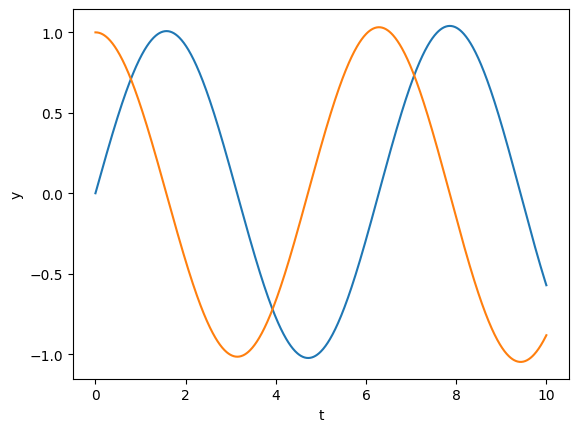

In [7]:
dt = 0.01 # time step
T = 10    # time span
n = int(T/dt)  # steps
t = np.linspace(0, T, n+1)
y = euler(second, [0, 1], dt, n, [0, -1, 0])
plt.plot(t, y);
plt.xlabel('t'); plt.ylabel('y');

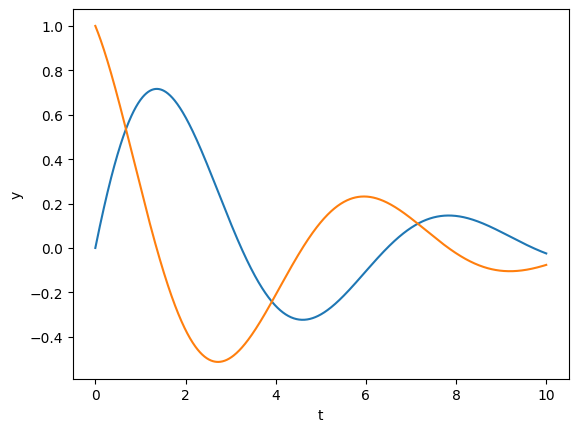

In [8]:
y = euler(second, [0, 1], dt, n, [0, -1, -0.5])
plt.plot(t, y)
plt.xlabel('t'); plt.ylabel('y');

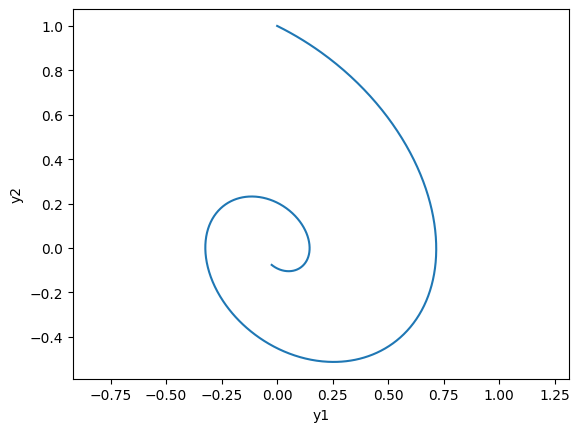

In [9]:
# phase plot
plt.plot(y[:,0], y[:,1]);
plt.xlabel('y1'); plt.ylabel('y2'); plt.axis('equal');

Let us see how the time step affects the accuracy of the solution.

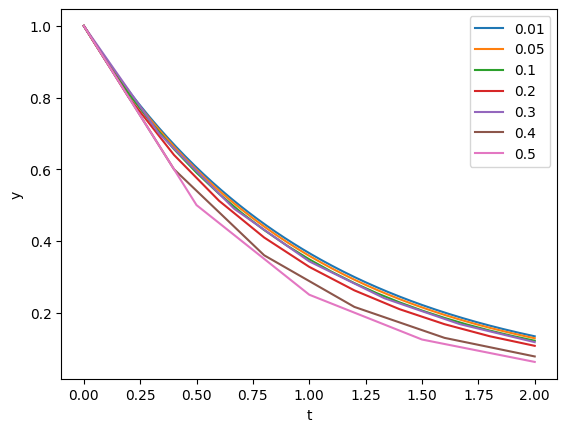

In [10]:
steps = [0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
T = 2
a = -1
for dt in steps:
    n = int(T/dt)  # steps
    t = np.linspace(0, T, n+1)
    y = euler(first, 1, dt, n, a)
    plt.plot(t,y)
plt.xlabel('t'); plt.ylabel('y'); plt.legend(steps);

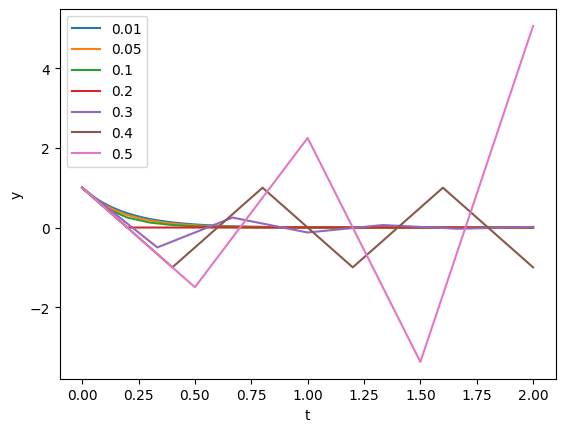

In [11]:
a = -5
for dt in steps:
    n = int(T/dt)  # steps
    t = np.linspace(0, T, n+1)
    y = euler(first, 1, dt, n, a)
    plt.plot(t,y)
plt.xlabel('t'); plt.ylabel('y'); plt.legend(steps);

## Scipy's Integrate package
To avoid numerical instability and to improve accuracy and efficiency, there are advanced methods for ODE solutions.
* Backward Euler method: solve

$$ y(t+\Delta t) = y(t) + f(y(t+\Delta t)) \Delta t$$

* Mixture of forward and backward (Crank-Nicolson):

$$ y(t+\Delta t) = y(t) + \frac{1}{2}\{f(y(t))+f(y(t+\Delta t))\} \Delta t$$

* Runge-Kutta method: minimize higher-order erros by Taylor expansion

$$ y(t+\Delta t) = y(t) + f(y(t))\Delta t + \frac{1}{2} \frac{d}{dt}f(y(t))\Delta t^2 + ...$$

* Adative time step: adjust $\Delta t$ depending on the scale of $\frac{df(y(t))}{dt}$.

The implementation and choice of these methods require a good expertise, but fortunately `scipy` includes `integrate` package which has been well tested and optimized.  
[`odeint()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.odeint.html) implements automatic method switching and time step adaptation.  
Alternatively, you can use a new function [`solve_ivp()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html), with a different function definition as `f(t, y)`.

In [12]:
from scipy.integrate import odeint

In [14]:
help(odeint)

Help on function odeint in module scipy.integrate._odepack_py:

odeint(
    func,
    y0,
    t,
    args=(),
    Dfun=None,
    col_deriv=0,
    full_output=0,
    ml=None,
    mu=None,
    rtol=None,
    atol=None,
    tcrit=None,
    h0=0.0,
    hmax=0.0,
    hmin=0.0,
    ixpr=0,
    mxstep=0,
    mxhnil=0,
    mxordn=12,
    mxords=5,
    printmessg=0,
    tfirst=False
)
    Integrate a system of ordinary differential equations.

    .. note:: For new code, use `scipy.integrate.solve_ivp` to solve a
              differential equation.

    Solve a system of ordinary differential equations using lsoda from the
    FORTRAN library odepack.

    Solves the initial value problem for stiff or non-stiff systems
    of first order ode-s::

        dy/dt = func(y, t, ...)  [or func(t, y, ...)]

    where y can be a vector.

    .. note:: By default, the required order of the first two arguments of
              `func` are in the opposite order of the arguments in the system
             

Here is an example of first-order linear ODE.

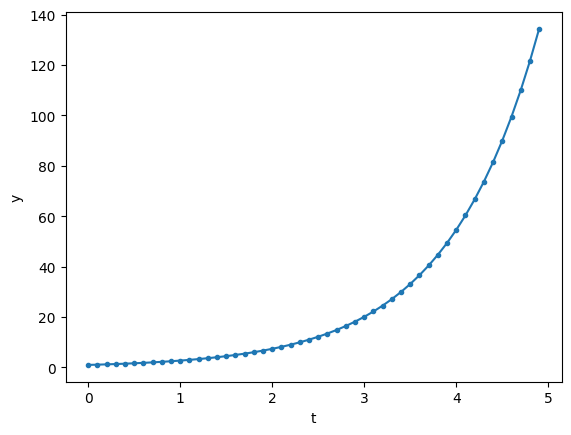

In [13]:
t = np.arange(0, 5, 0.1)  # time points
y = odeint(first, 1, t, args=(1,))
plt.plot(t, y, '.-');
plt.xlabel('t'); plt.ylabel('y');

Here's another example of second-order linear ODE.

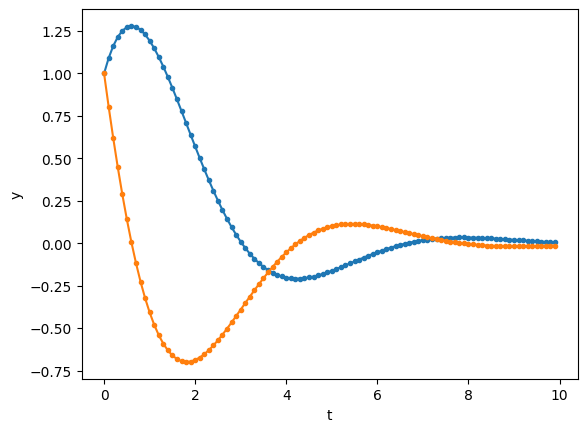

In [15]:
t = np.arange(0, 10, 0.1)  # time points
y = odeint(second, [1, 1], t, args=([0, -1, -1],))
plt.plot(t, y, '.-');
plt.xlabel('t'); plt.ylabel('y');

`odeint()` internally uses adaptive time steps, and returns values of `y` for time points specified in `t` by interpolation.

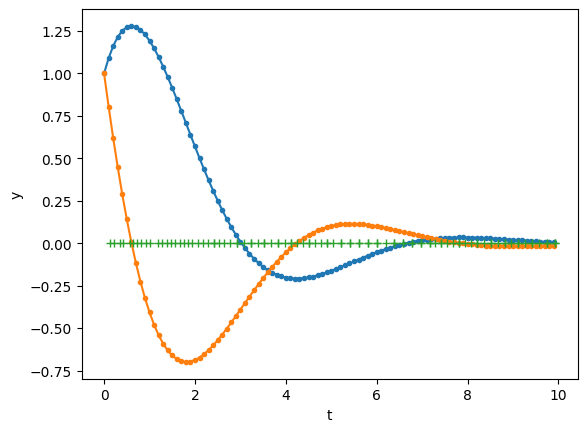

In [16]:
# If you are interested in the internal time steps used...
t = np.arange(0, 10, 0.1)  # time points
y, info = odeint(second, [1, 1], t, args=([0, -1, -1],), full_output=1)
#y, info = odeint(first, 1, t, args=(-1,), full_output=1)
plt.plot(t, y, '.-')
# the crosses show the time points actually used
plt.plot(info['tcur'], np.zeros_like(info['tcur']), '+');
plt.xlabel('t'); plt.ylabel('y');

## Fixed Point and Stability
A point $y$ that satisfy $\frac{d}{dt}{\bf y}=f({\bf y})={\bf 0}$ is called a *fixed point*.

A fixed point is characterized by its *stability*.

In [17]:
def expos(a, b):
    """Exponentials exp(a*t), exp(b*t)"""
    u = np.array(np.exp(a*t))
    v = np.array(np.exp(b*t))
    x = np.array([u, -u, -u, u]).T
    y = np.array([v, v, -v, -v]).T
    return x, y

def spirals(a, b):
    """Spirals: exp(a*t)*cos(b*t), exp(a*t)*sin(b*t) """
    u = np.array(np.exp(a*t)*np.cos(b*t))
    v = np.array(np.exp(a*t)*np.sin(b*t))
    x = np.array([u, v, -u, -v]).T
    y = np.array([v, -u, -v, u]).T
    return x, y

def arrowcurves(x, y, s=0.1):
    """curves with an arrowhead
    x, y: time courses in columns
    s: arrowhead size"""
    plt.plot(x, y)
    n = x.shape[1]  # columns
    for i in range(n):
        plt.arrow(x[-2,i], y[-2,i], x[-1,i]-x[-2,i], y[-1,i]-y[-2,i],
                 head_width=s, head_length=s)
    plt.axis('equal')


In [18]:
t = np.linspace(0, 1)  # time points

* Stable
    - Attractor
    - Neutrally stable

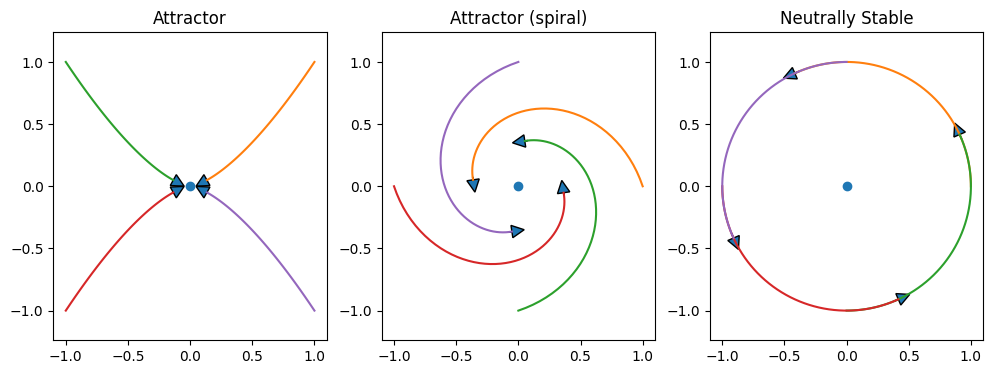

In [19]:
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.title('Attractor')
plt.plot(0, 0, 'o')
x, y = expos(-2, -3)
arrowcurves(x, y)
plt.subplot(1,3,2)
plt.title('Attractor (spiral)')
plt.plot(0, 0, 'o')
x, y = spirals(-1, 3)
arrowcurves(x,y)
plt.subplot(1,3,3)
plt.title('Neutrally Stable')
plt.plot(0, 0, 'o')
x, y = spirals(0, 2)
arrowcurves(x,y)

* Unstable
    - repellor
    - Saddle

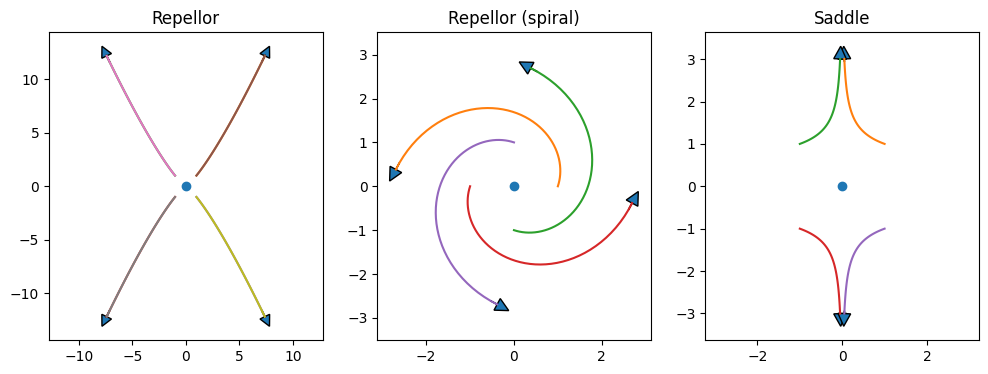

In [20]:
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.title('Repellor')
plt.plot(0, 0, 'o')
x, y = expos(2, 2.5)
arrowcurves(x, y, s=1)
arrowcurves(x, y)
plt.subplot(1,3,2)
plt.title('Repellor (spiral)')
plt.plot(0, 0, 'o')
x, y = spirals(1, 3)
arrowcurves(x, y, s=0.3)
plt.subplot(1,3,3)
plt.title('Saddle')
plt.plot(0, 0, 'o')
x, y = expos(-3, 1.1)
arrowcurves(x, y, s=0.3)

## Linear dynamical system

For a linear dynamical system

$$ \frac{d}{dt}{\bf y} = A {\bf y} $$

where ${\bf y}$ is an $n$ dimensional vector and $A$ is an $n\times n$ matrix, the origin ${\bf y}={\bf 0}$ is always a fixed point.
Its stability is determined by the eigenvalues of $A$.

* If the real part of all the eigenvalues are negative or zero, the system is stable.

* If any of the real part of the eigenvalues is positive, the system is unstable.

* If there are complex eigenvalues, the solution is oscillatory.

In [21]:
def linear(y, t, A):
    """Linear dynamcal system dy/dt = Ay
    y: n-dimensional state vector
    t: time (not used, for compatibility with odeint())
    A: n*n matrix"""
    # y is an array (row vector), A is a matrix
    return A@y

def lode_plot(A, y0=[1,0]):
    """Plot the trajectory and eiven values of linear ode"""
    ev,_ = np.linalg.eig(A)
    print('A =', A, '\nev =', ev)
    t=np.arange(0, 10, 0.1)
    y = odeint(linear, y0, t, args=(A,))
    plt.plot(y[0,0], y[0,1], 'o')   # starting point
    plt.plot(y[:,0], y[:,1], '.-')  # trajectory
    plt.plot(y[-1,0], y[-1,1], '*')  # end point
    plt.axis('equal')

Try different settings of A.

A = [[-1, 1], [-1, 0]] 
ev = [-0.5+0.8660254j -0.5-0.8660254j]


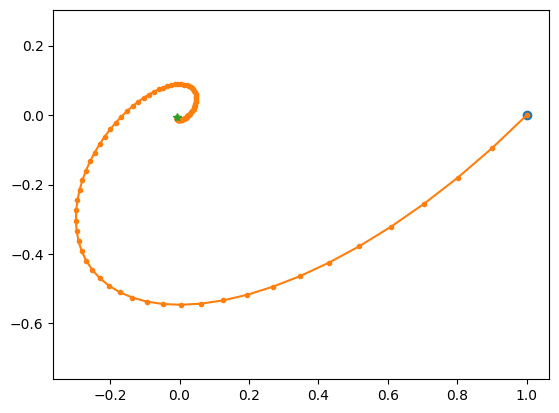

In [22]:
# spiral in
lode_plot([[-1, 1], [-1, 0]])

A = [[1, 1], [-1, 0]] 
ev = [0.5+0.8660254j 0.5-0.8660254j]


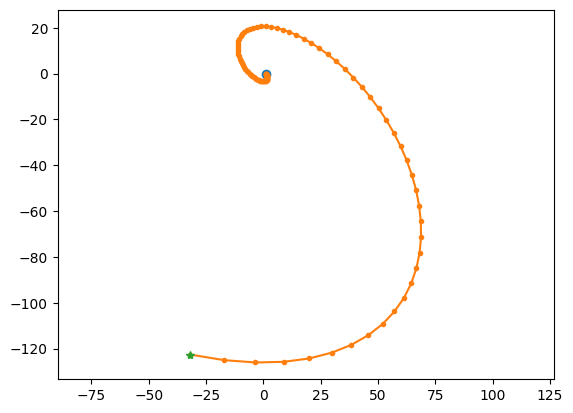

In [23]:
# spiral out
lode_plot([[1, 1], [-1, 0]])

A = [[1, 10], [-1, 0]] 
ev = [0.5+3.122499j 0.5-3.122499j]


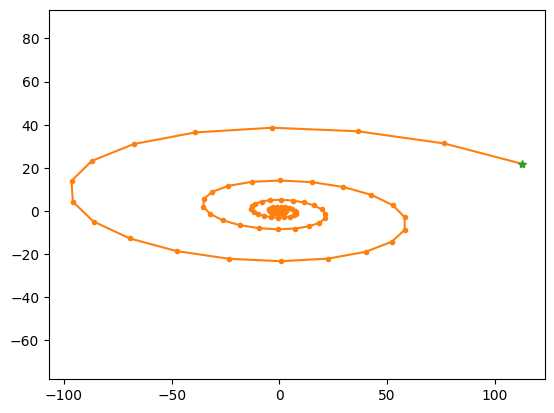

In [25]:
# spiral out
lode_plot([[1, 10], [-1, 0]])

A = [[-1, 0], [0, 1]] 
ev = [-1.  1.]


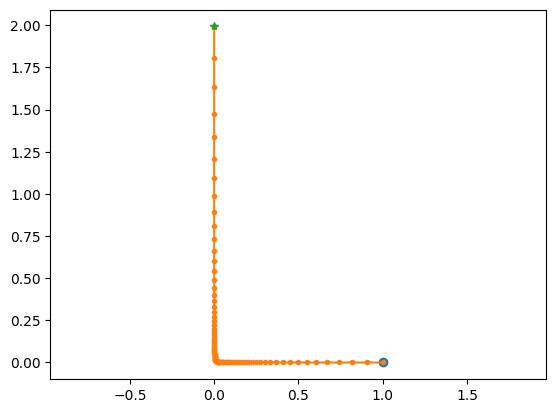

In [24]:
# saddle point
lode_plot([[-1, 0], [0, 1]], [1,0.0001])

## Nonlinear ODEs
While the dynamics of a linear ODE can show only convergence, divergence, or neutrally stable oscillations, nonlinear ODEs can show limit-cycle oscillation and chaos.

### Van der Pol oscillator
This is a classic equation describing an oscillator circuit with a vacuume tube:

$$ \frac{d^2y}{dt^2} - \mu(1-y^2)\frac{dy}{dt} + y = 0 $$

This can be converted into a 2D system as

$$ \frac{dy_1}{dt} = y_2 $$

$$ \frac{dy_2}{dt} = \mu(1-y_1^2)y_2 - y_1 $$

In [26]:
def vdp(y, t, mu=1.):
    """Van der Pol equation"""
    y1, y2 = y
    return np.array([y2, mu*(1 - y1**2)*y2 - y1])

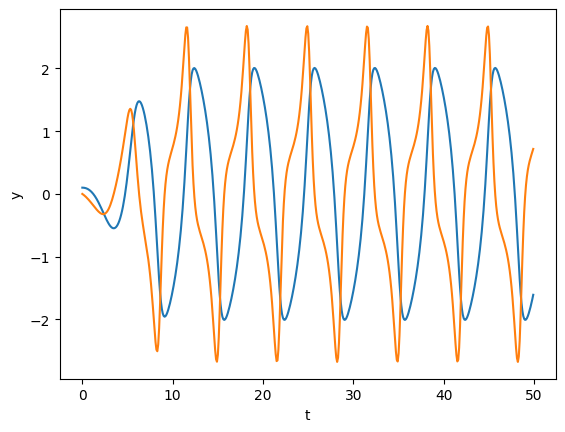

In [27]:
t = np.arange(0, 50, 0.1)
y = odeint(vdp, [0.1, 0], t)
plt.plot(t, y);
plt.xlabel('t'); plt.ylabel('y');

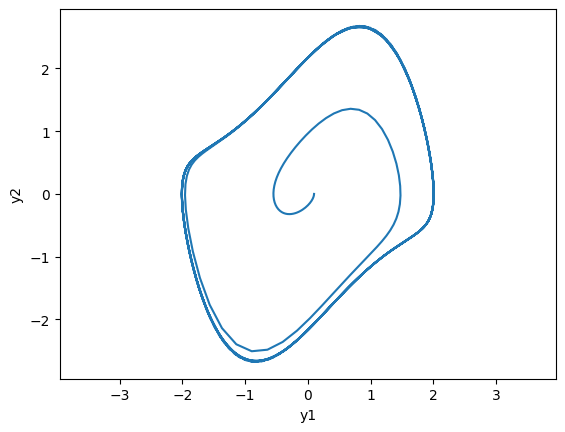

In [28]:
# phase plot
plt.plot(y[:,0], y[:,1]);
plt.xlabel('y1'); plt.ylabel('y2'); plt.axis('equal');

### Nullclines
The dynamincs in a 2D space is well characterized by the *nullclines*, the lines where $\frac{dy_i}{dt}=0$.

For the Van del Pol oscillator, they are given by:


$$ \frac{dy_1}{dt} = 0 \rightarrow y_2 = 0 $$

$$ \frac{dy_2}{dt} = 0 \rightarrow y_2 = \frac{y_1}{\mu(1-y_1^2)} $$

Above the $\frac{dy_1}{dt} = 0$ nullcline, $\frac{dy_1}{dt} > 0$, so the points move toward the right, and below the nullcline, points move toward left.  
On the right side of the $\frac{dy_2}{dt} = 0$ nullcline in the center, $\frac{dy_2}{dt} > 0$, so the points move downward, and  on the left side, points move upward.

The crosspoint of the two nullclines is a fixed point $\frac{dy_1}{dt} = \frac{dy_2}{dt} = 0$.

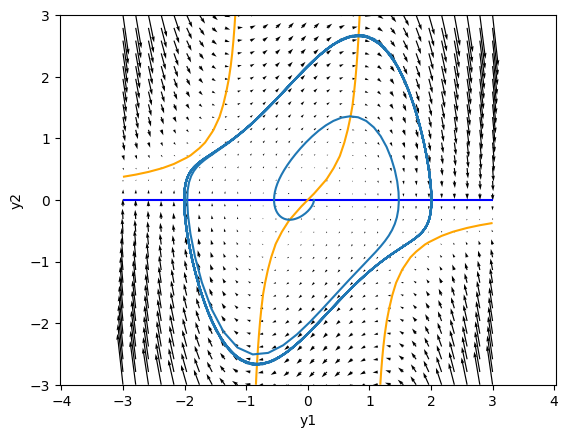

In [29]:
m = 30
x = np.linspace(-3, 3, m)
X, Y = np.meshgrid(x, x)
mu = 1
Z = vdp([X, Y], 1, mu)
plt.contour(X, Y, Z[0], levels=[0], colors='blue')  # dy1/dt = 0
plt.contour(X, Y, Z[1], levels=[0], colors='orange')  #dy2/dt = 0
plt.quiver(X, Y, Z[0], Z[1])   # vector field
y = odeint(vdp, [0.1, 0], t, args=(mu,))  # solve ODE
plt.plot(y[:,0], y[:,1]);  # solution
plt.xlabel('y1'); plt.ylabel('y2'); plt.axis('equal');

The stability of the fixed point is determined by the eigenvalues of the *linearized* system

$$ \frac{d\b{x}}{dt} = A \b{x} $$

where $A = \p{\b{f}(\b{y})}{\b{y}}$ is the Jacobian matrix at the fixed point.

For the Van der Pol oscillator, the Jacobian at the fixed point $\b{y}=(0,0)^T$ is:

$$ A = \mat{0 & 1 \\ -2\mu y_1 - 1 & \mu(1-y_1^2)} = \mat{0 & 1 \\ -1 & \mu}  $$

Its eigenvalues are $\mu/2 + \sqrt{\mu^2/4-1}$, which is complex with positive real part for $\mu<2$, makeing the trajectory near the fixed point spiraling out.


In [30]:
A = np.array([[0, 1], [-1, mu]])
np.linalg.eig(A)

EigResult(eigenvalues=array([0.5+0.8660254j, 0.5-0.8660254j]), eigenvectors=array([[0.70710678+0.j        , 0.70710678-0.j        ],
       [0.35355339+0.61237244j, 0.35355339-0.61237244j]]))

Please try with different values of $\mu$.

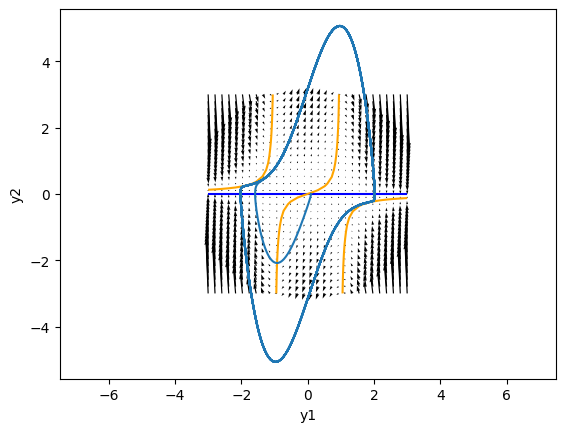

In [37]:
m = 30
x = np.linspace(-3, 3, m)
X, Y = np.meshgrid(x, x)
mu = 3
Z = vdp([X, Y], 1, mu)
plt.contour(X, Y, Z[0], levels=[0], colors='blue')  # dy1/dt = 0
plt.contour(X, Y, Z[1], levels=[0], colors='orange')  #dy2/dt = 0
plt.quiver(X, Y, Z[0], Z[1])   # vector field
y = odeint(vdp, [0.1, 0], t, args=(mu,))  # solve ODE
plt.plot(y[:,0], y[:,1]);  # solution
plt.xlabel('y1'); plt.ylabel('y2'); plt.axis('equal');

### Periodic orbit and Limit cycle
If a trajectry comes back to itself $y(t+T) = y(t)$ after some period $T$, it is called a *periodic orbit*.  
If trajectories around it converges to a periodic orbit, it is called a *limit cycle*.

*Poincaré-Bendixon theorem*: In a continuous 2D dynamical system, if a solution stay within a closed set with no fixed point, it converges to a periodic orbit.  
It implies that there is no chaos in a continuous 2D dynamic system.

### Lorenz attractor
Edward Lorenz derived a simplified equation describing the convection of atmosphere and found that it shows non-periodic oscillation.

$$ \frac{dx}{dt} = p(y - x) $$

$$ \frac{dy}{dt} = -xz + rx - y $$

$$ \frac{dz}{dt} = xy - bz $$

In [31]:
def lorenz(xyz, t, p=10., r=28., b=8./3):
    """Lorenz equation"""
    x, y, z = xyz
    dxdt = p*(y - x)
    dydt = -x*z + r*x - y
    dzdt = x*y - b*z
    return np.array([dxdt, dydt, dzdt])

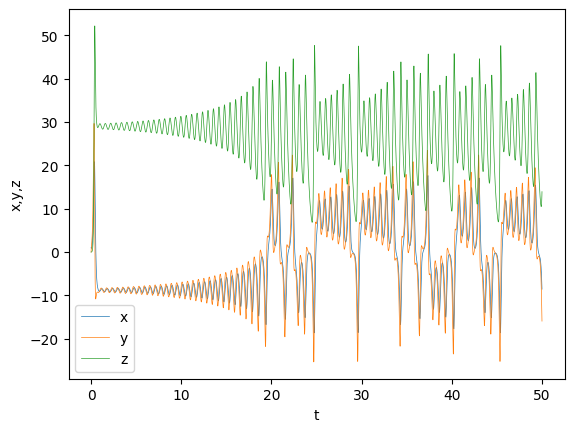

In [32]:
y0 = np.array([1, 0, 0])
t = np.arange(0, 50, 0.01)
y = odeint(lorenz, y0, t, args=(10., 30., 8./3))
plt.plot(t, y, lw=0.5);
plt.xlabel('t'); plt.ylabel('x,y,z'); plt.legend(('x','y','z'));

In [ ]:
# Uncomment below for interactive viewing
#%matplotlib widget

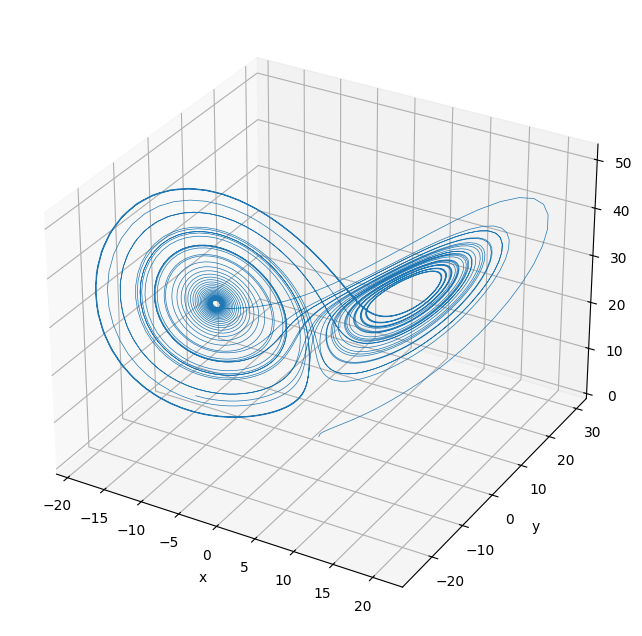

In [33]:
# Plot in 3D
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(projection='3d')
ax.plot(y[:,0], y[:,1], y[:,2], lw=0.5);
plt.xlabel('x'); plt.ylabel('y'); ax.set_zlabel('z');